# Thuật toán phân cụm BIRCH

## 1. Giới thiệu

Notebook trình bày nguyên lý và cài đặt BIRCH bằng Python theo hướng đối tượng.
Thực nghiệm sử dụng dữ liệu khách hàng bán lẻ mô phỏng: 30.000 khách với hai
đặc trưng, 20.000 khách với tám đặc trưng và 20 điểm để minh họa tính CF, tách cây.

### Dữ liệu và nhãn tham chiếu

G1–G5 là mã của năm cấu hình được đặt trước theo số đơn hàng, giá trị đơn
và mức sử dụng khuyến mãi. Đây là các giả định mô phỏng phục vụ thực nghiệm.
G1 có ít đơn, G4 có nhiều đơn, G5 có giá trị đơn cao; G3 có tỷ lệ dùng khuyến mãi cao.
Đặc điểm của G2 và các nhãn còn lại được kiểm tra bằng bảng `group_summary`
tính trực tiếp từ CSV ở mục 3, thay vì đặt tên theo các phân khúc kinh doanh.

Bảng thống kê ghi số khách của từng nhãn trong hai tập dữ liệu. Với tập 8D,
số đơn trung bình tính trên toàn bộ khách; trung vị của cột giá trị đơn trung bình
và trung bình tỷ lệ dùng khuyến mãi chỉ tính trên khách có ít nhất một đơn.

Các cấu hình có chồng lấn: khách mang nhãn khác nhau vẫn có thể có đặc trưng
gần nhau. Ví dụ minh họa, hai khách cùng có 4 đơn và chi 1.200 nghìn VND nhưng
khác tỷ lệ dùng khuyến mãi sẽ trùng vị trí trên đồ thị 2D. Vì vậy, hai đặc trưng
không mô tả đầy đủ hành vi mua sắm.

GX ký hiệu khoảng 1% bản ghi bổ sung có phạm vi số đơn và giá trị đơn rộng hơn.
GX không được xem là một cụm đồng nhất hay bằng chứng mọi bản ghi đó là ngoại lệ.

Nhãn tham chiếu được gán khi chuẩn bị dữ liệu, không phải kết quả BIRCH.
Cột `nhom_khach_hang_mo_phong` chỉ dùng để tính ARI/NMI, không đưa vào ma trận
đặc trưng. Mã cụm dự đoán không tương ứng trực tiếp với G1–G5.
K=5 là lựa chọn thí nghiệm theo thiết kế dữ liệu, chưa chứng minh có đúng năm cụm tự nhiên.


In [1]:
from pathlib import Path
from dataclasses import dataclass, field
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

ROOT = Path(".")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 100})
pd.set_option("display.max_columns", 20)
SEED, K, B, REPEATS = 42, 5, 30, 3
THRESHOLDS = {"2D": 0.35, "8D": 1.10}
FEATURES_2D = ["so_don_hang_thang", "tong_chi_tieu_thang_nghin_vnd"]
FEATURES_8D = FEATURES_2D + [
    "gia_tri_don_trung_binh_nghin_vnd", "so_ngay_tu_lan_mua_cuoi",
    "so_luot_xem_san_pham_thang", "ty_le_don_dung_khuyen_mai",
    "so_nhom_hang_da_mua", "so_don_hoan_tra_6_thang"]
SMALL_FEATURES = ["so_don_hang_thang", "so_ngay_tu_lan_mua_cuoi"]

def show_save(fig, filename):
    fig.savefig(OUT / filename, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 2. CF và CF Tree

Phân cụm là bài toán học không giám sát, nhóm các điểm theo mức tương đồng.
Trong bài này, mỗi khách hàng là một vector đặc trưng và sử dụng khoảng cách
Euclidean. Nhãn mô phỏng chỉ dùng để đánh giá kết quả.

### Công thức CF

Một Clustering Feature tóm tắt tập điểm C bằng ba đại lượng:

$$CF=(N,LS,SS),\qquad N=|C|,\quad LS=\sum_{i\in C}x_i,
\quad SS=\sum_{i\in C}\|x_i\|^2.$$

N là số điểm, LS là vector tổng theo từng chiều, SS là một số vô hướng.
Tâm và bán kính được tính bằng:

$$\mu=\frac{LS}{N},\qquad R^2=\frac{SS}{N}-\|\mu\|^2.$$

R là căn trung bình bình phương khoảng cách đến tâm, không phải khoảng cách
lớn nhất. Code dùng `max(R_squared, 0)` để tránh giá trị âm nhỏ do làm tròn.
Hai CF của các tập không giao nhau có thể cộng theo từng thành phần.

### Cách xây cây

CF Tree gồm các nút chứa CF Entry. Entry ở lá đại diện một micro-cluster;
entry ở nút trong lưu CF tóm tắt và liên kết tới nút con.

1. Chọn entry có tâm gần điểm mới nhất, đi từ gốc xuống lá.
2. Cộng thử CF của điểm vào entry gần nhất. Nếu bán kính sau gộp không vượt
   threshold thì hấp thụ; nếu vượt thì tạo entry mới.
3. Khi số entry vượt branching factor, chọn hai tâm xa nhất làm hai seed,
   rồi chia các entry theo seed gần hơn.
4. Cập nhật CF cha. Nếu cha đầy thì tiếp tục tách; gốc đầy thì tạo gốc mới.
5. Lấy CF ở các lá, gom micro-cluster bằng weighted K-Means và gán nhãn.

## 3. Đọc và khám phá dữ liệu

Ba tập CSV gồm dữ liệu 2D, 8D và 20 điểm minh họa. Phần dưới hiển thị
kích thước, năm dòng đầu mỗi tập và thống kê mô tả các đặc trưng 8D.
Bảng `group_summary` mô tả các nhãn tham chiếu có sẵn trong CSV.


In [2]:
data2 = pd.read_csv(ROOT / "data/khach_hang_2d.csv")
data8 = pd.read_csv(ROOT / "data/khach_hang_8d.csv")
small = pd.read_csv(ROOT / "data/minh_hoa_birch.csv")
print("2D:", data2.shape, "| 8D:", data8.shape, "| Minh họa:", small.shape)
display(data2.head(5))
display(data8.head(5))
display(small.head(5))

display(Markdown("**Thống kê tám đặc trưng của tập 8D**"))
display(data8[FEATURES_8D].describe()
        .loc[["mean", "std", "min", "50%", "max"]].round(2))
# Thống kê đặc trưng theo nhãn mô phỏng.
label_column = "nhom_khach_hang_mo_phong"
grouped = data8.groupby(label_column)
active = data8[data8.so_don_hang_thang > 0].groupby(label_column)
group_summary = grouped.agg(
    customers_8d=("ma_khach_hang", "size"),
    mean_orders_8d=("so_don_hang_thang", "mean"),
)
group_summary["median_order_value_8d"] = (
    active["gia_tri_don_trung_binh_nghin_vnd"].median()
)
group_summary["mean_promotion_ratio_8d"] = (
    active["ty_le_don_dung_khuyen_mai"].mean()
)
group_summary["customers_2d"] = data2.groupby(label_column).size()
display(Markdown("**Thống kê theo nhãn mô phỏng (giá trị đơn: nghìn VND)**"))
display(group_summary.round(4))


2D: (30000, 4) | 8D: (20000, 11) | Minh họa: (20, 3)


,ma_khach_hang,so_don_hang_thang,tong_chi_tieu_thang_nghin_vnd,nhom_khach_hang_mo_phong
0,A000001,1,322.81,G3
1,A000002,1,247.23,G2
2,A000003,16,7706.56,G4
3,A000004,1,245.59,G3
4,A000005,1,103.97,G1


,ma_khach_hang,khu_vuc,so_don_hang_thang,tong_chi_tieu_thang_nghin_vnd,gia_tri_don_trung_binh_nghin_vnd,so_ngay_tu_lan_mua_cuoi,so_luot_xem_san_pham_thang,ty_le_don_dung_khuyen_mai,so_nhom_hang_da_mua,so_don_hoan_tra_6_thang,nhom_khach_hang_mo_phong
0,B000001,Bac,7,834.33,119.19,13,109,0.714286,2,0,G3
1,B000002,Nam,1,167.06,167.06,18,8,0.000000,1,0,G1
2,B000003,Trung,1,228.31,228.31,0,14,1.000000,1,0,G1
3,B000004,Nam,8,3258.00,407.25,7,82,0.125000,6,3,G4
4,B000005,Bac,6,3245.76,540.96,3,46,0.166667,2,0,G2


,ma_khach_hang,so_don_hang_thang,so_ngay_tu_lan_mua_cuoi
0,MH01,1,2
1,MH02,1,4
2,MH03,2,3
3,MH04,2,2
4,MH05,5,8


**Thống kê tám đặc trưng của tập 8D**

,so_don_hang_thang,tong_chi_tieu_thang_nghin_vnd,gia_tri_don_trung_binh_nghin_vnd,so_ngay_tu_lan_mua_cuoi,so_luot_xem_san_pham_thang,ty_le_don_dung_khuyen_mai,so_nhom_hang_da_mua,so_don_hoan_tra_6_thang
mean,3.68,1832.13,303.38,35.17,49.73,0.33,3.19,0.83
std,4.67,5225.19,314.04,49.02,46.20,0.38,2.03,1.31
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,2.00,598.33,253.18,19.00,34.00,0.19,3.00,0.00
max,45.00,132580.35,2997.60,363.00,372.00,1.00,12.00,11.00


**Thống kê theo nhãn mô phỏng (giá trị đơn: nghìn VND)**

,customers_8d,mean_orders_8d,median_order_value_8d,mean_promotion_ratio_8d,customers_2d
nhom_khach_hang_mo_phong,,,,,
G1,7488,0.7959,221.36,0.3109,11261
G2,5191,2.9852,328.63,0.3499,7669
G3,3545,4.4990,239.54,0.8174,5471
G4,2393,10.1738,416.04,0.2999,3540
G5,1186,6.1071,973.54,0.1514,1785
GX,197,23.4010,1499.30,0.3861,274


In [3]:
def scatter_clusters(X, labels, title, xlabel, ylabel, centers=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    for j, label in enumerate(np.unique(labels)):
        mask = labels == label
        ax.scatter(X[mask, 0], X[mask, 1], s=9, alpha=0.45,
                   color=plt.get_cmap("tab10")(j % 10), label=str(label), rasterized=True)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=75,
                   edgecolors="white", linewidths=0.7, label="Tâm cụm")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend(fontsize=8, title="Nhãn", loc="best")
    return ax

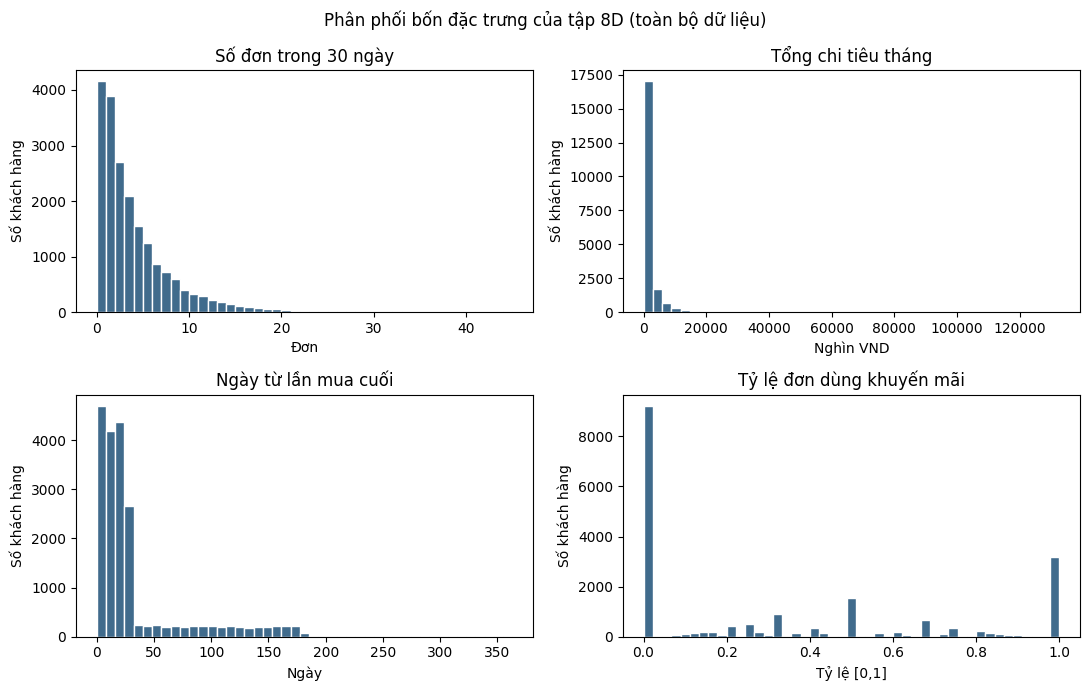

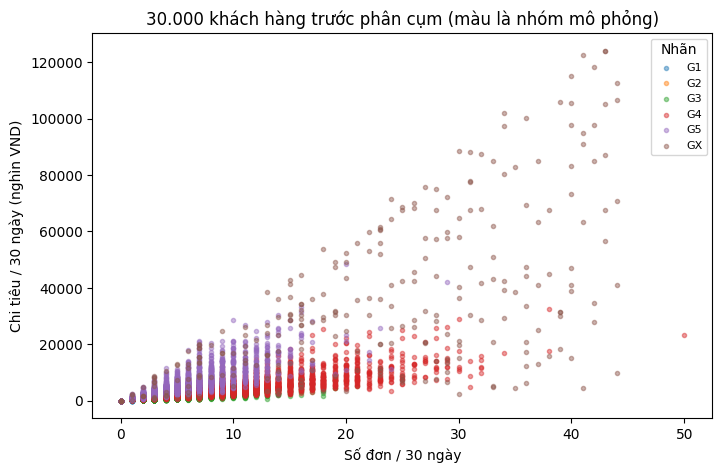

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
columns = [FEATURES_8D[i] for i in [0, 1, 3, 5]]
titles = ["Số đơn trong 30 ngày", "Tổng chi tiêu tháng", "Ngày từ lần mua cuối", "Tỷ lệ đơn dùng khuyến mãi"]
units = ["Đơn", "Nghìn VND", "Ngày", "Tỷ lệ [0,1]"]
for ax, column, title, unit in zip(axes.flat, columns, titles, units):
    ax.hist(data8[column], bins=45, color="#406b8c", edgecolor="white")
    ax.set(title=title, xlabel=unit, ylabel="Số khách hàng")
fig.suptitle("Phân phối bốn đặc trưng của tập 8D (toàn bộ dữ liệu)")
fig.tight_layout()
show_save(fig, "phan_phoi_dac_trung.png")

fig, ax = plt.subplots(figsize=(8, 5))
scatter_clusters(data2[FEATURES_2D].to_numpy(), data2.nhom_khach_hang_mo_phong.to_numpy(),
                 "30.000 khách hàng trước phân cụm (màu là nhóm mô phỏng)",
                 "Số đơn / 30 ngày", "Chi tiêu / 30 ngày (nghìn VND)", ax=ax)
show_save(fig, "du_lieu_2d_truoc_phan_cum.png")

## 4. Tiền xử lý và chuẩn hóa

Chỉ các đặc trưng số được đưa vào ma trận phân cụm. Mã khách, khu vực và
nhãn mô phỏng được tách riêng. Tổng chi tiêu có thang đo lớn hơn số đơn,
nên sử dụng Z-score trước khi tính khoảng cách:

$$z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.$$

Sử dụng [StandardScaler](https://scikit-learn.org/1.9/modules/generated/sklearn.preprocessing.StandardScaler.html) của scikit-learn để tính trung bình và độ lệch chuẩn
theo cột với quy ước `ddof=0`. Với cột hằng, hệ số chia bằng 1 nên giá trị sau
khi trừ trung bình bằng 0. Mỗi dataset dùng một scaler riêng.
Các thuật toán trong cùng bảng so sánh dùng chung ma trận đã chuẩn hóa.

Chuẩn hóa không loại bỏ tương quan giữa các cột. Với khách hàng mới, cần
dùng lại trung bình và độ lệch chuẩn đã học từ dữ liệu ban đầu.
Thư viện được dùng cho tiền xử lý, PCA, vẽ biểu đồ và các chỉ số đánh giá.
CF, CF Tree, chèn điểm, tách nút và weighted K-Means trong BIRCH được tự cài đặt.


In [5]:
from sklearn.preprocessing import StandardScaler


,mean_raw,std_raw,mean_z,std_z
so_don_hang_thang,3.6802,4.6720,-0.0,1.0
tong_chi_tieu_thang_nghin_vnd,1832.1317,5225.0641,0.0,1.0
gia_tri_don_trung_binh_nghin_vnd,303.3758,314.0359,0.0,1.0
so_ngay_tu_lan_mua_cuoi,35.1699,49.0182,0.0,1.0
so_luot_xem_san_pham_thang,49.7342,46.2010,-0.0,1.0
ty_le_don_dung_khuyen_mai,0.3321,0.3802,-0.0,1.0
so_nhom_hang_da_mua,3.1940,2.0338,0.0,1.0
so_don_hoan_tra_6_thang,0.8264,1.3122,0.0,1.0


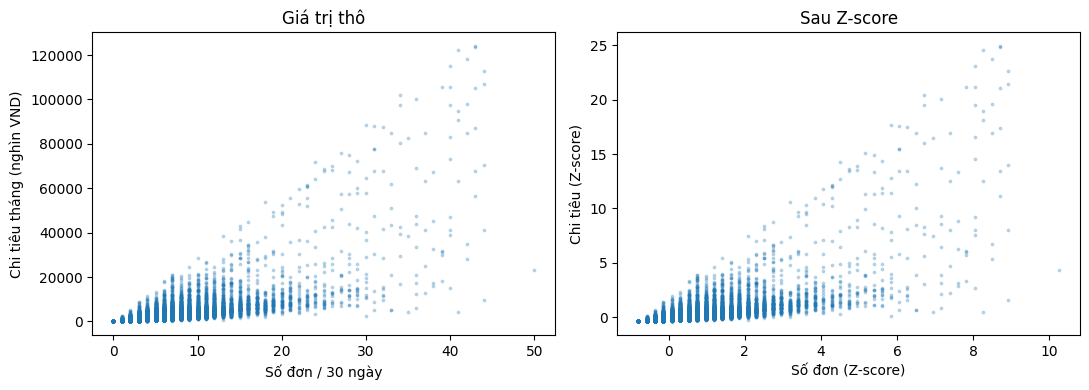

In [6]:
raw2, raw8 = data2[FEATURES_2D].to_numpy(float), data8[FEATURES_8D].to_numpy(float)
truth2, truth8 = data2.nhom_khach_hang_mo_phong.to_numpy(), data8.nhom_khach_hang_mo_phong.to_numpy()
scaler2, scaler8 = StandardScaler(), StandardScaler()
X2, X8 = scaler2.fit_transform(raw2), scaler8.fit_transform(raw8)
assert np.isfinite(X2).all() and np.isfinite(X8).all()
np.testing.assert_allclose(X8.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(X8.std(axis=0), 1, atol=1e-12)
display(pd.DataFrame({"mean_raw": scaler8.mean_, "std_raw": np.sqrt(scaler8.var_),
                      "mean_z": X8.mean(axis=0), "std_z": X8.std(axis=0)}, index=FEATURES_8D).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(raw2[:, 0], raw2[:, 1], s=3, alpha=0.25)
axes[0].set(title="Giá trị thô", xlabel="Số đơn / 30 ngày", ylabel="Chi tiêu tháng (nghìn VND)")
axes[1].scatter(X2[:, 0], X2[:, 1], s=3, alpha=0.25)
axes[1].set(title="Sau Z-score", xlabel="Số đơn (Z-score)", ylabel="Chi tiêu (Z-score)")
fig.tight_layout()
show_save(fig, "truoc_sau_chuan_hoa.png")

## 5. Cài đặt BIRCH bằng OOP

Phần cài đặt gồm `ClusteringFeature`, `CFEntry`, `CFNode`, `CFTree` và `Birch`.
NumPy được dùng cho phép toán số; phần BIRCH tự viết không gọi thuật toán
phân cụm đóng gói.

- `threshold`: bán kính RMS tối đa của CF lá sau khi thử gộp.
- `branching_factor`: số entry tối đa trong mỗi nút.
- `n_clusters`: số cụm ở bước gom toàn cục; `None` giữ từng micro-cluster.

Phiên bản này xây CF Tree, gom cụm toàn cục và gán nhãn. Các pha tái xây cây
theo giới hạn bộ nhớ và tinh chỉnh của BIRCH nguyên bản chưa được cài đặt.

### CF và cấu trúc nút

`ClusteringFeature` tính N, LS, SS, tâm và bán kính. `CFEntry` chứa một CF
và liên kết con; `CFNode.summary()` cộng các CF để cập nhật thống kê của cha.

In [7]:
def _matrix(X, n_features=None, allow_empty=False):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] == 0:
        raise ValueError("X must have shape (n_samples, n_features), n_features > 0")
    if not allow_empty and len(X) == 0:
        raise ValueError("X must contain at least one sample")
    if n_features is not None and X.shape[1] != n_features:
        raise ValueError("Unexpected number of features")
    if not np.isfinite(X).all():
        raise ValueError("X contains NaN or Inf")
    return X


@dataclass
class ClusteringFeature:
    n: int
    ls: np.ndarray
    ss: float

    @classmethod
    def from_points(cls, X):
        X = _matrix(X)
        return cls(len(X), X.sum(axis=0), float(np.sum(X * X)))

    def __add__(self, other):
        if self.ls.shape != other.ls.shape:
            raise ValueError("CF dimensions differ")
        return ClusteringFeature(self.n + other.n, self.ls + other.ls,
                                 self.ss + other.ss)

    @property
    def centroid(self):
        return self.ls / self.n

    @property
    def radius_squared(self):
        center = self.centroid
        return max(float(self.ss / self.n - center @ center), 0.0)

    @property
    def radius(self):
        return float(np.sqrt(self.radius_squared))

    def as_dict(self):
        return {"N": self.n, "LS": self.ls.tolist(), "SS": self.ss,
                "centroid": self.centroid.tolist(), "radius": self.radius}


@dataclass
class CFEntry:
    cf: ClusteringFeature
    child: "CFNode | None" = None


@dataclass
class CFNode:
    is_leaf: bool
    entries: list = field(default_factory=list)

    def summary(self):
        if not self.entries:
            raise ValueError("Empty node has no CF summary")
        total = self.entries[0].cf
        for entry in self.entries[1:]:
            total = total + entry.cf
        return total

### Chèn điểm và tách CF Tree

`_insert` đi theo entry gần nhất và thử hấp thụ ở lá. Nút đầy được tách
bằng `_split`; kết quả tách được trả lên để thay entry cũ bằng hai entry mới.
Mỗi CF cha được tính lại từ các nút con. `validate()` kiểm tra giới hạn
số entry, độ sâu lá, threshold và sự nhất quán của CF.

In [8]:
class CFTree:
    def __init__(self, threshold=0.5, branching_factor=30, record_trace=False):
        if not np.isfinite(threshold) or threshold < 0:
            raise ValueError("threshold must be finite and nonnegative")
        if (isinstance(branching_factor, bool)
                or not isinstance(branching_factor, (int, np.integer))
                or branching_factor < 2):
            raise ValueError("branching_factor must be an integer >= 2")
        self.threshold = float(threshold)
        self.branching_factor = int(branching_factor)
        self.record_trace = record_trace
        self.root = CFNode(is_leaf=True)
        self.n_features = None
        self.history = []
        self.split_counts = {"leaf": 0, "internal": 0, "root": 0}

    def snapshot(self):
        def visit(node):
            return {"is_leaf": node.is_leaf, "entries": [
                {"cf": e.cf.as_dict(),
                 "child": visit(e.child) if e.child is not None else None}
                for e in node.entries]}
        return visit(self.root)

    def insert(self, point):
        point = np.asarray(point, dtype=float)
        if point.ndim != 1 or not len(point) or not np.isfinite(point).all():
            raise ValueError("point must be a finite, nonempty vector")
        if self.n_features is None:
            self.n_features = len(point)
        if len(point) != self.n_features:
            raise ValueError("Unexpected number of features")
        before = self.snapshot() if self.record_trace else None
        events = [] if self.record_trace else None
        cf = ClusteringFeature(1, point.copy(), float(point @ point))
        split = self._insert(self.root, cf, events)
        if split is not None:
            self.root = CFNode(False, [CFEntry(node.summary(), node) for node in split])
            self.split_counts["root"] += 1
            if events is not None:
                events.append({"action": "split_root"})
        if self.record_trace:
            self.history.append({"point": point.tolist(), "before": before,
                                 "events": events, "after": self.snapshot()})

    def _insert(self, node, point_cf, events):
        if not node.entries:
            node.entries.append(CFEntry(point_cf))
            if events is not None:
                events.append({"action": "new_entry", "before_cf": None,
                               "after_cf": point_cf.as_dict(), "candidate_radius": 0.0})
            return None
        centers = np.array([e.cf.centroid for e in node.entries])
        index = int(np.argmin(np.sum((centers - point_cf.centroid) ** 2, axis=1)))
        closest = node.entries[index]
        if node.is_leaf:
            merged = closest.cf + point_cf
            accepted = merged.radius <= self.threshold
            if events is not None:
                events.append({"action": "absorb" if accepted else "new_entry",
                               "before_cf": closest.cf.as_dict(),
                               "after_cf": (merged if accepted else point_cf).as_dict(),
                               "candidate_radius": merged.radius})
            if accepted:
                closest.cf = merged
            else:
                node.entries.append(CFEntry(point_cf))
        else:
            split = self._insert(closest.child, point_cf, events)
            if split is None:
                closest.cf = closest.child.summary()
            else:
                node.entries[index:index + 1] = [CFEntry(n.summary(), n) for n in split]
        if len(node.entries) > self.branching_factor:
            return self._split(node, events)
        return None

    def _split(self, node, events):
        centers = np.array([e.cf.centroid for e in node.entries])
        distances = np.sum((centers[:, None, :] - centers[None, :, :]) ** 2, axis=2)
        # Hai seed xa nhất, cố định mỗi seed vào một phía để tránh nút rỗng khi khoảng cách bằng nhau.
        np.fill_diagonal(distances, -1)
        a, b = np.unravel_index(np.argmax(distances), distances.shape)
        left, right = CFNode(node.is_leaf), CFNode(node.is_leaf)
        for i, entry in enumerate(node.entries):
            if i == a:
                left.entries.append(entry)
            elif i == b:
                right.entries.append(entry)
            elif distances[i, a] <= distances[i, b]:
                left.entries.append(entry)
            else:
                right.entries.append(entry)
        kind = "leaf" if node.is_leaf else "internal"
        self.split_counts[kind] += 1
        if events is not None:
            events.append({"action": "split_" + kind,
                           "seeds": [centers[a].tolist(), centers[b].tolist()],
                           "left_N": left.summary().n, "right_N": right.summary().n})
        return left, right

    def micro_clusters(self):
        result = []
        def visit(node):
            for entry in node.entries:
                if node.is_leaf:
                    result.append(entry.cf)
                else:
                    visit(entry.child)
        visit(self.root)
        return result

    def validate(self):
        """Kiểm tra số entry, độ sâu lá, CF cha và ngưỡng bán kính ở lá."""
        depths = set()
        nodes = 0
        def visit(node, depth):
            nonlocal nodes
            nodes += 1
            assert 1 <= len(node.entries) <= self.branching_factor
            for entry in node.entries:
                assert entry.cf.n >= 1
                if node.is_leaf:
                    assert entry.child is None
                    assert entry.cf.radius <= self.threshold + 1e-7
                    depths.add(depth)
                else:
                    assert entry.child is not None
                    child_cf = visit(entry.child, depth + 1)
                    assert entry.cf.n == child_cf.n
                    np.testing.assert_allclose(entry.cf.ls, child_cf.ls, rtol=1e-10, atol=1e-8)
                    np.testing.assert_allclose(entry.cf.ss, child_cf.ss, rtol=1e-10, atol=1e-8)
            return node.summary()
        total = visit(self.root, 0)
        assert len(depths) == 1
        return {"N": total.n, "nodes": nodes, "height": next(iter(depths)) + 1,
                "micro_clusters": len(self.micro_clusters()), **self.split_counts}

### Khoảng cách và weighted K-Means

Mỗi micro-cluster có tâm $c_i$ và trọng số $N_i$. Bước gom cuối tối thiểu hóa:

$$J=\sum_i N_i\|c_i-v_{g(i)}\|^2.$$

Trọng số N giúp một CF có nhiều khách đóng góp tương ứng vào tâm cụm.
Hàm tự viết dùng khởi tạo k-means++ có trọng số, thử 5 lần và thực hiện tối
đa 100 vòng gán–cập nhật mỗi lần. Phép tính này làm việc trên centroid CF.

In [9]:
def _squared_distances(X, centers):
    return np.maximum(np.sum(X * X, axis=1)[:, None]
                      + np.sum(centers * centers, axis=1)[None, :]
                      - 2 * X @ centers.T, 0.0)


def nearest_centers(X, centers, batch_size=1024):
    """Giới hạn ma trận khoảng cách ở batch_size x số tâm."""
    labels = np.empty(len(X), dtype=int)
    for start in range(0, len(X), batch_size):
        labels[start:start + batch_size] = _squared_distances(
            X[start:start + batch_size], centers).argmin(axis=1)
    return labels


def weighted_kmeans(X, weights, k, random_state=42, n_init=5, max_iter=100):
    """Lloyd trên centroid CF, trọng số N; khởi tạo k-means++ có trọng số."""
    rng = np.random.default_rng(random_state)
    best = None
    for _ in range(n_init):
        chosen = [int(rng.choice(len(X), p=weights / weights.sum()))]
        while len(chosen) < k:
            d2 = _squared_distances(X, X[chosen]).min(axis=1)
            probs = weights * d2
            probs[chosen] = 0
            if probs.sum() <= 1e-15:
                remaining = np.setdiff1d(np.arange(len(X)), chosen)
                chosen.append(int(remaining[0]))
            else:
                chosen.append(int(rng.choice(len(X), p=probs / probs.sum())))
        centers = X[chosen].copy()
        for _ in range(max_iter):
            distances = _squared_distances(X, centers)
            labels = distances.argmin(axis=1)
            updated = centers.copy()
            for j in range(k):
                mask = labels == j
                if mask.any():
                    updated[j] = np.average(X[mask], axis=0, weights=weights[mask])
                else:
                    residual = weights * distances.min(axis=1)
                    updated[j] = X[int(np.argmax(residual))]
            converged = np.allclose(centers, updated, atol=1e-7, rtol=0)
            centers = updated
            if converged:
                break
        distances = _squared_distances(X, centers)
        labels = distances.argmin(axis=1)
        objective = float(np.sum(weights * distances[np.arange(len(X)), labels]))
        if best is None or objective < best[0]:
            best = objective, centers.copy(), labels.copy()
    return best[1], best[2], best[0]

### Lớp Birch

`fit` xây cây, lấy micro-cluster rồi gom thành các cụm cuối. `predict_micro`
tìm centroid CF gần nhất; `predict` tra nhãn toàn cục của CF đó. Việc gán nhãn
được chia theo batch để hạn chế kích thước ma trận khoảng cách trung gian.

In [10]:
class Birch:
    def __init__(self, threshold=0.5, branching_factor=30, n_clusters=5,
                 random_state=42, record_trace=False, compute_labels=True):
        if n_clusters is not None and (isinstance(n_clusters, bool)
                or not isinstance(n_clusters, (int, np.integer)) or n_clusters < 1):
            raise ValueError("n_clusters must be None or a positive integer")
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.n_clusters = n_clusters
        self.random_state = random_state
        self.record_trace = record_trace
        self.compute_labels = compute_labels

    def fit(self, X):
        X = _matrix(X)
        self.n_features_in_ = X.shape[1]
        self.tree_ = CFTree(self.threshold, self.branching_factor, self.record_trace)
        for point in X:
            self.tree_.insert(point)
        self.micro_clusters_ = self.tree_.micro_clusters()
        self.subcluster_centers_ = np.array([cf.centroid for cf in self.micro_clusters_])
        self.subcluster_weights_ = np.array([cf.n for cf in self.micro_clusters_], dtype=float)
        if self.n_clusters is None:
            self.cluster_centers_ = self.subcluster_centers_.copy()
            self.subcluster_labels_ = np.arange(len(self.micro_clusters_))
            self.global_objective_ = 0.0
        else:
            k = min(self.n_clusters, len(self.micro_clusters_))
            (self.cluster_centers_, self.subcluster_labels_,
             self.global_objective_) = weighted_kmeans(
                self.subcluster_centers_, self.subcluster_weights_, k, self.random_state)
        self.n_clusters_ = len(np.unique(self.subcluster_labels_))
        if hasattr(self, "labels_"):
            del self.labels_
        if self.compute_labels:
            self.labels_ = self.predict(X)
        return self

    def predict_micro(self, X):
        if not hasattr(self, "tree_"):
            raise ValueError("Call fit before predict")
        X = _matrix(X, self.n_features_in_, allow_empty=True)
        return nearest_centers(X, self.subcluster_centers_)

    def predict(self, X):
        micro_labels = self.predict_micro(X)
        return self.subcluster_labels_[micro_labels]

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_ if self.compute_labels else self.predict(X)

## 6. Minh họa trên 20 khách hàng

Ví dụ dùng số đơn tháng và số ngày từ lần mua cuối, giữ giá trị thô để tính
tay. Đặt T=1, B=2, K=3.

| Điểm đã chèn | N | LS | SS | Tâm | R² |
|---|---:|---|---:|---|---|
| (1; 2) | 1 | (1; 2) | 5 | (1; 2) | 0 |
| thêm (1; 4) | 2 | (2; 6) | 22 | (1; 3) | 22/2 − 10 = 1 |
| thêm (2; 3) | 3 | (4; 9) | 35 | (4/3; 3) | 35/3 − 97/9 = 8/9 |

Điểm thứ hai được hấp thụ vì R=T=1. Điểm thứ ba cũng được hấp thụ vì
R≈0,9428. Sau khi thêm (2; 2), CF=(4, (6; 11), 43).
Nếu gộp tiếp (5; 8), bán kính mới có R²=7,12 và R≈2,6683>T, nên tạo entry mới.

Ở bước 9, sau khi chèn (9; 3), lá có ba entry trong khi B=2.
Ba tâm A=(1,5; 2,75), B=(5,5; 8,75), C=(9; 3) có khoảng cách bình phương
d²(A,B)=52; d²(A,C)=56,3125; d²(B,C)=45,3125. Chọn A và C làm seed,
đưa B về phía C. Hai lá mới có N=4 và N=5; gốc mới giữ tổng N=9.

Code sau đối chiếu CF bằng `assert` và ghi lại từng lần chèn. Các hình cây
được dựng từ trạng thái `before` và `after` trong lịch sử thực thi.

In [11]:
small_X = small[SMALL_FEATURES].to_numpy(float)
small_model = Birch(threshold=1, branching_factor=2, n_clusters=3,
                    random_state=SEED, record_trace=True).fit(small_X)
manual_cf = ClusteringFeature.from_points(small_X[:3])
assert manual_cf.n == 3 and manual_cf.ss == 35
np.testing.assert_allclose(manual_cf.ls, [4, 9])
np.testing.assert_allclose(manual_cf.radius_squared, 8 / 9)
display(pd.DataFrame([ClusteringFeature.from_points(small_X[:i]).as_dict() for i in [1, 2, 3, 4]]))
assert small_model.tree_.history[4]["events"][0]["candidate_radius"] > 1
trace_rows = []
for step, record in enumerate(small_model.tree_.history, 1):
    event = record["events"][0]
    trace_rows.append({"step": step, "point": record["point"],
                       "decision": event["action"], "candidate_radius": event["candidate_radius"],
                       "CF_before": event["before_cf"], "CF_after": event["after_cf"],
                       "split_events": [e["action"] for e in record["events"][1:]]})
trace_table = pd.DataFrame(trace_rows)
with pd.option_context("display.max_colwidth", 160):
    display(trace_table)
small_stats = small_model.tree_.validate()
assert small_stats["leaf"] >= 1 and small_stats["internal"] >= 1 and small_stats["root"] >= 1
display(small_stats)

,N,LS,SS,centroid,radius
0,1,"[1.0, 2.0]",5.0,"[1.0, 2.0]",0.000000
1,2,"[2.0, 6.0]",22.0,"[1.0, 3.0]",1.000000
2,3,"[4.0, 9.0]",35.0,"[1.3333333333333333, 3.0]",0.942809
3,4,"[6.0, 11.0]",43.0,"[1.5, 2.75]",0.968246


,step,point,decision,candidate_radius,CF_before,CF_after,split_events
0,1,"[1.0, 2.0]",new_entry,0.000000,None,"{'N': 1, 'LS': [1.0, 2.0], 'SS': 5.0, 'centroid': [1.0, 2.0], 'radius': 0.0}",[]
1,2,"[1.0, 4.0]",absorb,1.000000,"{'N': 1, 'LS': [1.0, 2.0], 'SS': 5.0, 'centroid': [1.0, 2.0], 'radius': 0.0}","{'N': 2, 'LS': [2.0, 6.0], 'SS': 22.0, 'centroid': [1.0, 3.0], 'radius': 1.0}",[]
2,3,"[2.0, 3.0]",absorb,0.942809,"{'N': 2, 'LS': [2.0, 6.0], 'SS': 22.0, 'centroid': [1.0, 3.0], 'radius': 1.0}","{'N': 3, 'LS': [4.0, 9.0], 'SS': 35.0, 'centroid': [1.3333333333333333, 3.0], 'radius': 0.9428090415820626}",[]
3,4,"[2.0, 2.0]",absorb,0.968246,"{'N': 3, 'LS': [4.0, 9.0], 'SS': 35.0, 'centroid': [1.3333333333333333, 3.0], 'radius': 0.9428090415820626}","{'N': 4, 'LS': [6.0, 11.0], 'SS': 43.0, 'centroid': [1.5, 2.75], 'radius': 0.9682458365518543}",[]
4,5,"[5.0, 8.0]",new_entry,2.668333,"{'N': 4, 'LS': [6.0, 11.0], 'SS': 43.0, 'centroid': [1.5, 2.75], 'radius': 0.9682458365518543}","{'N': 1, 'LS': [5.0, 8.0], 'SS': 89.0, 'centroid': [5.0, 8.0], 'radius': 0.0}",[]
5,6,"[5.0, 10.0]",absorb,1.000000,"{'N': 1, 'LS': [5.0, 8.0], 'SS': 89.0, 'centroid': [5.0, 8.0], 'radius': 0.0}","{'N': 2, 'LS': [10.0, 18.0], 'SS': 214.0, 'centroid': [5.0, 9.0], 'radius': 1.0}",[]
6,7,"[6.0, 9.0]",absorb,0.942809,"{'N': 2, 'LS': [10.0, 18.0], 'SS': 214.0, 'centroid': [5.0, 9.0], 'radius': 1.0}","{'N': 3, 'LS': [16.0, 27.0], 'SS': 331.0, 'centroid': [5.333333333333333, 9.0], 'radius': 0.9428090415820617}",[]
7,8,"[6.0, 8.0]",absorb,0.968246,"{'N': 3, 'LS': [16.0, 27.0], 'SS': 331.0, 'centroid': [5.333333333333333, 9.0], 'radius': 0.9428090415820617}","{'N': 4, 'LS': [22.0, 35.0], 'SS': 431.0, 'centroid': [5.5, 8.75], 'radius': 0.9682458365518543}",[]
8,9,"[9.0, 3.0]",new_entry,2.828427,"{'N': 4, 'LS': [22.0, 35.0], 'SS': 431.0, 'centroid': [5.5, 8.75], 'radius': 0.9682458365518543}","{'N': 1, 'LS': [9.0, 3.0], 'SS': 90.0, 'centroid': [9.0, 3.0], 'radius': 0.0}","[split_leaf, split_root]"
9,10,"[9.0, 5.0]",absorb,1.000000,"{'N': 1, 'LS': [9.0, 3.0], 'SS': 90.0, 'centroid': [9.0, 3.0], 'radius': 0.0}","{'N': 2, 'LS': [18.0, 8.0], 'SS': 196.0, 'centroid': [9.0, 4.0], 'radius': 1.0}",[]


{'N': 20,
 'nodes': 6,
 'height': 3,
 'micro_clusters': 5,
 'leaf': 2,
 'internal': 1,
 'root': 2}

In [12]:
def plot_tree(snapshot, title):
    positions, links, labels = {}, [], {}
    next_x = [0]
    def visit(node, depth, name):
        children = [(i, e["child"]) for i, e in enumerate(node["entries"]) if e["child"]]
        child_x = []
        for i, child in children:
            child_name = f"{name}.{i}"
            child_x.append(visit(child, depth + 1, child_name))
            links.append((name, child_name))
        x = float(np.mean(child_x)) if child_x else float(next_x[0])
        if not child_x:
            next_x[0] += 1
        positions[name] = (x, -depth)
        kind = "Lá" if node["is_leaf"] else "Trong"
        entry_text = [f"E{i}: N={e['cf']['N']}, μ={np.round(e['cf']['centroid'], 1)}"
                      for i, e in enumerate(node["entries"])]
        labels[name] = kind + "\n" + "\n".join(entry_text)
        return x
    visit(snapshot, 0, "R")
    fig, ax = plt.subplots(figsize=(max(8, next_x[0] * 2.8), 4.8))
    for parent, child in links:
        px, py = positions[parent]
        cx, cy = positions[child]
        ax.plot([px, cx], [py, cy], color="0.65", zorder=0)
    for name, (x, y) in positions.items():
        ax.text(x, y, labels[name], ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#eef3f7", edgecolor="0.4"))
    ax.set_xlim(-0.7, max(0.7, next_x[0] - 0.3))
    ax.set_ylim(min(y for _, y in positions.values()) - 0.6, 0.6)
    ax.set_title(title)
    ax.axis("off")
    return fig

**Bước 9, chèn [9.0, 3.0], sự kiện split_leaf.**

[{'action': 'new_entry',
  'before_cf': {'N': 4,
   'LS': [22.0, 35.0],
   'SS': 431.0,
   'centroid': [5.5, 8.75],
   'radius': 0.9682458365518543},
  'after_cf': {'N': 1,
   'LS': [9.0, 3.0],
   'SS': 90.0,
   'centroid': [9.0, 3.0],
   'radius': 0.0},
  'candidate_radius': 2.8284271247461903},
 {'action': 'split_leaf',
  'seeds': [[1.5, 2.75], [9.0, 3.0]],
  'left_N': 4,
  'right_N': 5},
 {'action': 'split_root'}]

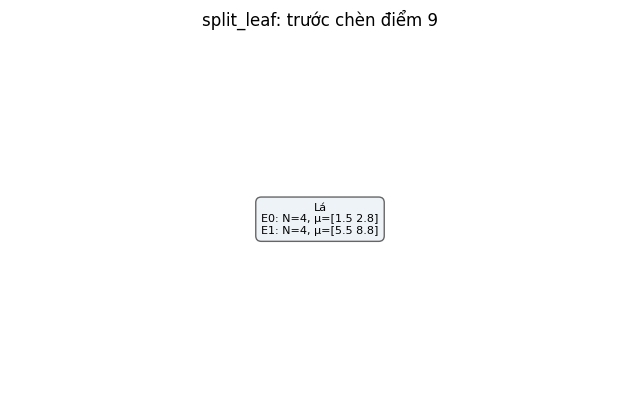

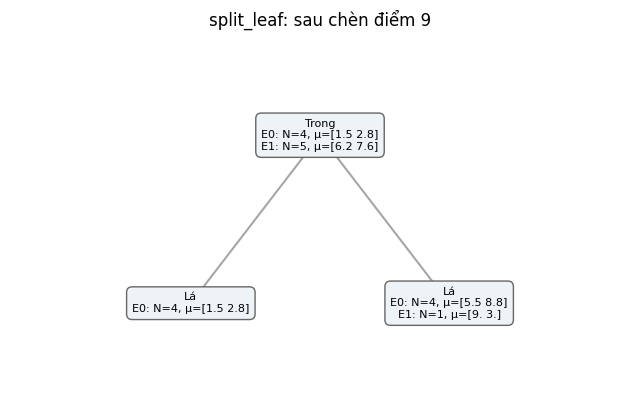

**Bước 13, chèn [13.0, 10.0], sự kiện split_internal.**

[{'action': 'new_entry',
  'before_cf': {'N': 4,
   'LS': [38.0, 15.0],
   'SS': 421.0,
   'centroid': [9.5, 3.75],
   'radius': 0.9682458365518543},
  'after_cf': {'N': 1,
   'LS': [13.0, 10.0],
   'SS': 269.0,
   'centroid': [13.0, 10.0],
   'radius': 0.0},
  'candidate_radius': 2.993325909419154},
 {'action': 'split_leaf',
  'seeds': [[5.5, 8.75], [13.0, 10.0]],
  'left_N': 8,
  'right_N': 1},
 {'action': 'split_internal',
  'seeds': [[1.5, 2.75], [13.0, 10.0]],
  'left_N': 4,
  'right_N': 9},
 {'action': 'split_root'}]

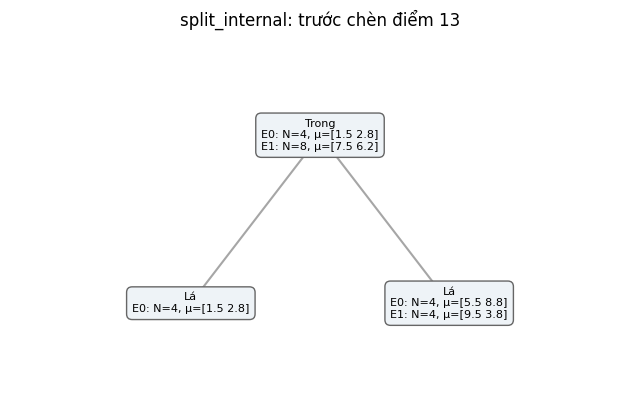

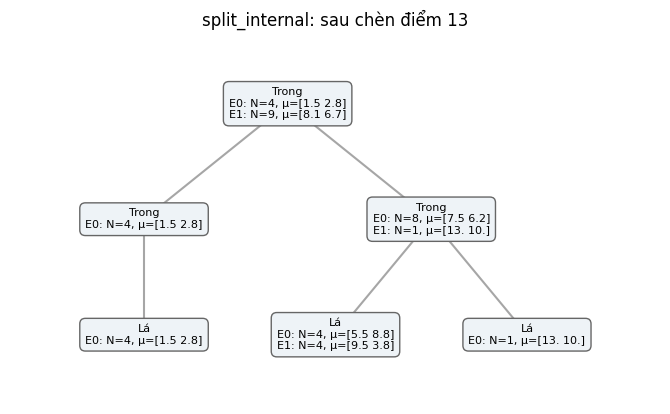

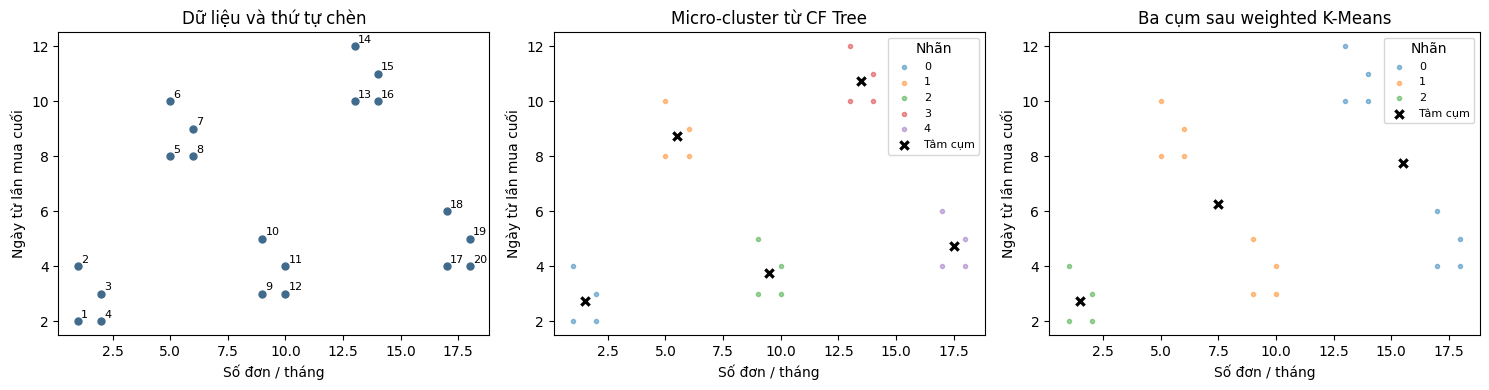

In [13]:
for split_kind in ["split_leaf", "split_internal"]:
    index, record = next((i, h) for i, h in enumerate(small_model.tree_.history)
                         if any(e["action"] == split_kind for e in h["events"]))
    display(Markdown(f"**Bước {index + 1}, chèn {record['point']}, sự kiện {split_kind}.**"))
    display(record["events"])
    for state in ["before", "after"]:
        title = f"{split_kind}: {'trước' if state == 'before' else 'sau'} chèn điểm {index + 1}"
        show_save(plot_tree(record[state], title), f"{split_kind}_{state}.png")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(small_X[:, 0], small_X[:, 1], color="#406b8c", s=25)
for i, point in enumerate(small_X):
    axes[0].annotate(str(i + 1), point + 0.13, fontsize=8)
axes[0].set(title="Dữ liệu và thứ tự chèn", xlabel="Số đơn / tháng", ylabel="Ngày từ lần mua cuối")
scatter_clusters(small_X, small_model.predict_micro(small_X), "Micro-cluster từ CF Tree",
                 "Số đơn / tháng", "Ngày từ lần mua cuối", small_model.subcluster_centers_, axes[1])
scatter_clusters(small_X, small_model.labels_, "Ba cụm sau weighted K-Means",
                 "Số đơn / tháng", "Ngày từ lần mua cuối", small_model.cluster_centers_, axes[2])
fig.tight_layout()
show_save(fig, "minh_hoa_20_khach_hang.png")

## 7. Phân cụm 30.000 khách hàng trong 2D

Dùng X2 đã chuẩn hóa với T=0,35, B=30, K=5. K được đặt bằng số cấu hình G1–G5 khi mô phỏng;
đây là lựa chọn thí nghiệm, chưa phải kết quả ước lượng số cụm. Màu trên biểu đồ là nhãn dự đoán; bảng trung bình
và trung vị sử dụng đơn vị gốc để mô tả từng cụm.

{'N': 30000,
 'nodes': 9,
 'height': 2,
 'micro_clusters': 175,
 'leaf': 7,
 'internal': 0,
 'root': 1}

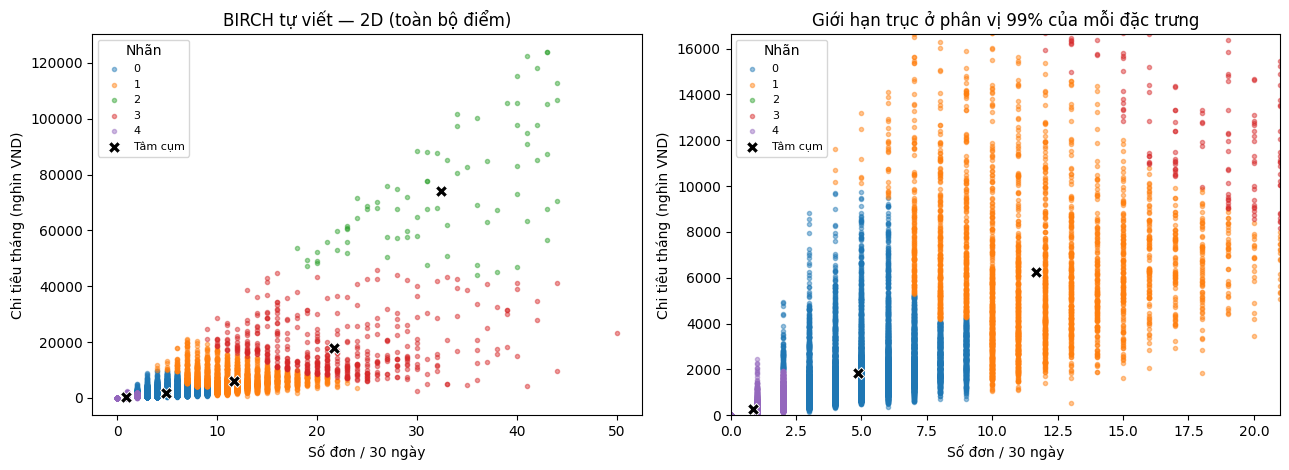

so_don_hang_thang               tong_chi_tieu_thang_nghin_vnd  \
                     size   mean median                          size   
cluster                                                                 
0                   10603   4.79    4.0                         10603   
1                    2767  11.53   11.0                          2767   
2                      77  32.42   32.0                            77   
3                     448  21.54   21.0                           448   
4                   16105   0.85    1.0                         16105   

                             
             mean    median  
cluster                      
0         1789.19   1420.52  
1         6183.22   5630.88  
2        74101.11  68178.76  
3        17593.35  15037.94  
4          249.95    195.65

In [14]:
model2 = Birch(THRESHOLDS["2D"], B, K, SEED).fit(X2)
stats2 = model2.tree_.validate()
display(stats2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
scatter_clusters(raw2, model2.labels_, "BIRCH tự viết — 2D (toàn bộ điểm)",
                 "Số đơn / 30 ngày", "Chi tiêu tháng (nghìn VND)",
                 scaler2.inverse_transform(model2.cluster_centers_), axes[0])
scatter_clusters(raw2, model2.labels_, "Giới hạn trục ở phân vị 99% của mỗi đặc trưng",
                 "Số đơn / 30 ngày", "Chi tiêu tháng (nghìn VND)",
                 scaler2.inverse_transform(model2.cluster_centers_), axes[1])
axes[1].set_xlim(0, np.quantile(raw2[:, 0], 0.99))
axes[1].set_ylim(0, np.quantile(raw2[:, 1], 0.99))
fig.tight_layout()
show_save(fig, "phan_cum_2d.png")

profile2 = data2[FEATURES_2D].assign(cluster=model2.labels_).groupby("cluster").agg(["size", "mean", "median"])
display(profile2.round(2))


## 8. Phân cụm 20.000 khách hàng trong 8D

Dùng đủ tám đặc trưng Z-score với T=1,10, B=30, K=5. [PCA](https://scikit-learn.org/1.9/modules/generated/sklearn.decomposition.PCA.html) được thực hiện
sau phân cụm và chỉ dùng để vẽ. Hai trục PC không mang đơn vị tiền hay ngày;
các cụm có thể chồng lên nhau trên hình chiếu.

{'N': 20000,
 'nodes': 22,
 'height': 2,
 'micro_clusters': 483,
 'leaf': 20,
 'internal': 0,
 'root': 1}

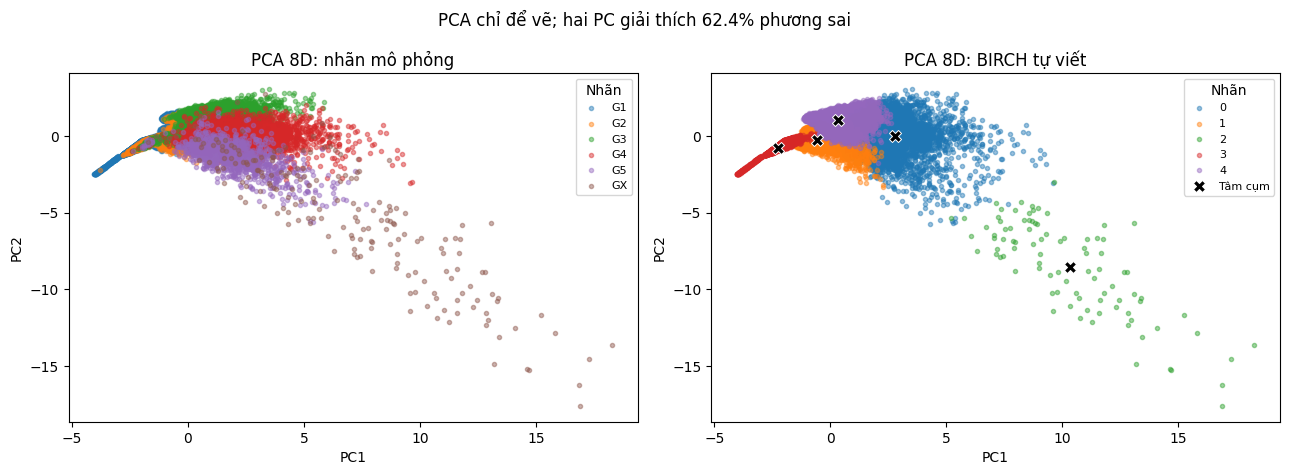

,so_khach_hang,so_don_hang_thang,tong_chi_tieu_thang_nghin_vnd,gia_tri_don_trung_binh_nghin_vnd,so_ngay_tu_lan_mua_cuoi,so_luot_xem_san_pham_thang,ty_le_don_dung_khuyen_mai,so_nhom_hang_da_mua,so_don_hoan_tra_6_thang
cluster,,,,,,,,,
0,3662,10.03,5377.33,562.71,14.57,113.70,0.37,5.50,2.52
1,6745,2.33,867.86,332.69,15.35,30.52,0.12,2.69,0.33
2,92,31.90,62895.47,2028.75,15.25,165.57,0.38,3.25,1.64
3,4031,0.00,0.00,0.00,115.63,10.62,0.00,1.79,0.11
4,5470,3.33,970.89,288.16,14.44,57.48,0.82,3.30,0.82


In [15]:
from sklearn.decomposition import PCA

model8 = Birch(THRESHOLDS["8D"], B, K, SEED).fit(X8)
stats8 = model8.tree_.validate()
display(stats8)
pca = PCA(n_components=2, svd_solver="full")
projection8 = pca.fit_transform(X8)
projected_centers8 = pca.transform(model8.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
scatter_clusters(projection8, truth8, "PCA 8D: nhãn mô phỏng", "PC1", "PC2", ax=axes[0])
scatter_clusters(projection8, model8.labels_, "PCA 8D: BIRCH tự viết", "PC1", "PC2",
                 projected_centers8, axes[1])
fig.suptitle(f"PCA chỉ để vẽ; hai PC giải thích {pca.explained_variance_ratio_.sum():.1%} phương sai")
fig.tight_layout()
show_save(fig, "phan_cum_8d_pca.png")
profile8 = data8[FEATURES_8D].assign(cluster=model8.labels_).groupby("cluster").mean()
profile8.insert(0, "so_khach_hang", pd.Series(model8.labels_).value_counts().reindex(profile8.index).to_numpy())
display(profile8.round(2))

## 9. So sánh BIRCH tự viết và scikit-learn

Hai bản nhận cùng dữ liệu, thứ tự điểm, T, B và K. Bản tự viết dùng weighted
K-Means ở bước cuối; [Birch của scikit-learn](https://scikit-learn.org/1.9/modules/generated/sklearn.cluster.Birch.html)
dùng Agglomerative khi K là số nguyên, nên kết quả có thể khác nhau.

Thời gian gồm `fit` và lấy nhãn, lặp 3 lần rồi lấy trung vị. Đọc CSV,
chuẩn hóa, vẽ và tính chỉ số nằm ngoài phép đo. [ARI](https://scikit-learn.org/1.9/modules/generated/sklearn.metrics.adjusted_rand_score.html) và
[NMI](https://scikit-learn.org/1.9/modules/generated/sklearn.metrics.normalized_mutual_info_score.html) được tính trên toàn
bộ nhãn; Silhouette dùng chung mẫu cố định tối đa 1.200 điểm cho mỗi bảng.

[Silhouette](https://scikit-learn.org/1.9/modules/generated/sklearn.metrics.silhouette_score.html) có công thức $s=(b-a)/\max(a,b)$, với a là khoảng cách trung bình
trong cụm và b là khoảng cách trung bình nhỏ nhất tới cụm khác.
Nếu không có ít nhất hai cụm hợp lệ, chương trình trả NaN.

In [16]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

def silhouette_indices(n, sample_size=1200, seed=42):
    return np.sort(np.random.default_rng(seed).choice(n, min(n, sample_size), replace=False))


def evaluate_labels(X, truth, labels, sample_indices):
    labels, truth = np.asarray(labels), np.asarray(truth)
    # ARI/NMI bao gồm -1 như một nhãn; silhouette loại nhiễu trên cùng tập chỉ số gốc.
    valid = sample_indices[labels[sample_indices] != -1]
    sampled_labels = labels[valid]
    k = len(np.unique(sampled_labels))
    score = np.nan
    if 2 <= k < len(valid):
        with threadpool_limits(limits=1):
            score = float(silhouette_score(X[valid], sampled_labels))
    return {"n_clusters": len(set(labels) - {-1}),
            "noise_fraction": float(np.mean(labels == -1)),
            "largest_cluster_fraction": float(max(np.unique(labels[labels != -1], return_counts=True)[1], default=0) / len(labels)),
            "ARI": float(adjusted_rand_score(truth, labels)),
            "NMI": float(normalized_mutual_info_score(truth, labels)),
            "Silhouette": score, "silhouette_n": len(valid)}


def run_benchmark(model, name, dataset, X, truth, sample_indices, repeats=1):
    times = []
    # Model BIRCH đặt compute_labels=False: fit rồi predict đúng một lần.
    # K-Means, DBSCAN và Agglomerative lấy labels_ đã tính trong fit.
    with threadpool_limits(limits=1):
        for _ in range(repeats):
            start = perf_counter()
            model.fit(X)
            labels = model.labels_.copy() if hasattr(model, "labels_") else model.predict(X)
            times.append(perf_counter() - start)
    row = {"dataset": dataset, "algorithm": name, "n_samples": len(X),
           "seconds": float(np.median(times)), "seconds_min": float(min(times)),
           "seconds_max": float(max(times)), "repeats": repeats,
           "n_micro_clusters": (len(model.subcluster_centers_)
                                if hasattr(model, "subcluster_centers_") else np.nan)}
    row.update(evaluate_labels(X, truth, labels, sample_indices))
    return row

In [17]:
def plot_benchmark(table, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    x = np.arange(len(table))
    axes[0].bar(x, table.seconds, color="#406b8c")
    axes[0].set(ylabel="Thời gian (giây)", title="Fit + gán nhãn")
    for j, metric in enumerate(["ARI", "NMI", "Silhouette"]):
        axes[1].bar(x + (j - 1) * 0.25, table[metric], width=0.25, label=metric)
    axes[1].set(ylabel="Giá trị chỉ số", title="Chất lượng phân cụm")
    axes[1].axhline(0, color="0.5", linewidth=0.6)
    axes[1].legend()
    for ax in axes:
        ax.set_xticks(x, table.algorithm, rotation=25, ha="right", fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    return fig

,dataset,algorithm,n_samples,seconds,seconds_min,seconds_max,repeats,n_micro_clusters,n_clusters,noise_fraction,largest_cluster_fraction,ARI,NMI,Silhouette,silhouette_n
0,2D,BIRCH tự viết,30000,2.1738,2.1522,2.3023,3,175,5,0.0,0.5368,0.3115,0.2967,0.5627,1200
1,2D,BIRCH sklearn,30000,0.5176,0.4652,0.5985,3,175,5,0.0,0.9914,0.0098,0.0386,0.7954,1200
2,8D,BIRCH tự viết,20000,2.0236,2.0112,2.1472,3,483,5,0.0,0.3372,0.2289,0.3146,0.2704,1200
3,8D,BIRCH sklearn,20000,0.3813,0.3715,0.3874,3,483,5,0.0,0.9432,0.0587,0.1519,0.4434,1200


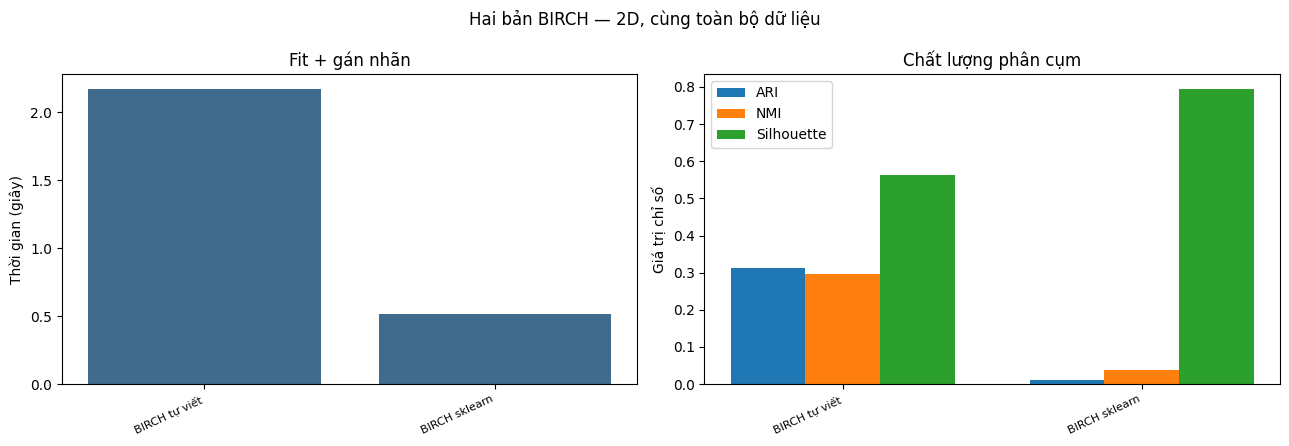

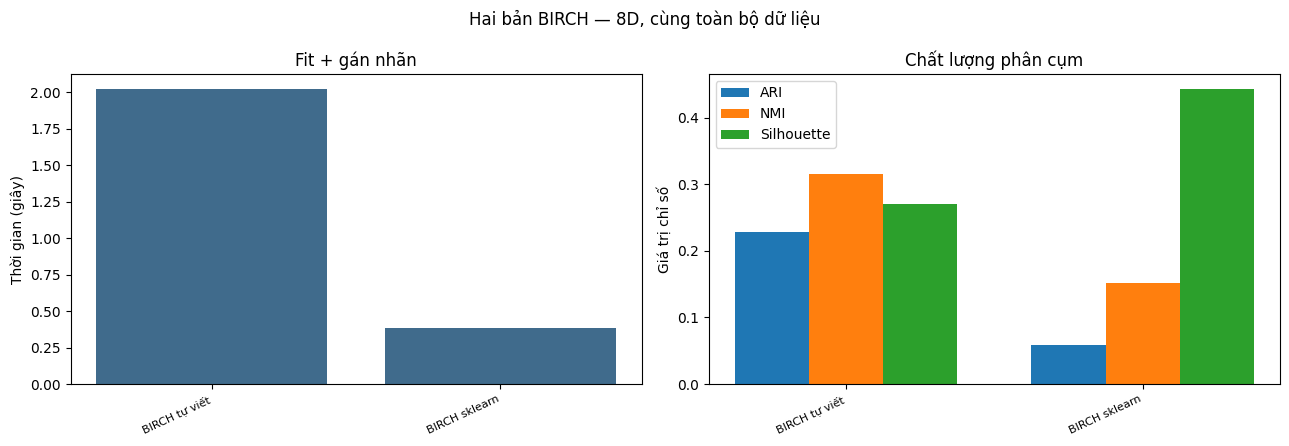

In [18]:
from sklearn.cluster import Birch as SklearnBirch, KMeans, DBSCAN, AgglomerativeClustering

full_rows = []
for name, X, truth in [("2D", X2, truth2), ("8D", X8, truth8)]:
    indices = silhouette_indices(len(X), seed=SEED)
    estimators = [
        ("BIRCH tự viết", Birch(THRESHOLDS[name], B, K, SEED, compute_labels=False)),
        ("BIRCH sklearn", SklearnBirch(threshold=THRESHOLDS[name], branching_factor=B,
                                       n_clusters=K, compute_labels=False))]
    for label, estimator in estimators:
        row = run_benchmark(estimator, label, name, X, truth, indices, REPEATS)
        full_rows.append(row)
full_results = pd.DataFrame(full_rows)
full_results.to_csv(OUT / "benchmark_birch_full.csv", index=False)
display(full_results.round(4))
for name in ["2D", "8D"]:
    show_save(plot_benchmark(full_results[full_results.dataset == name], f"Hai bản BIRCH — {name}, cùng toàn bộ dữ liệu"),
              f"benchmark_birch_{name}.png")

## 10. So sánh với K-Means, DBSCAN và Agglomerative

Mỗi dataset lấy cố định 3.000 điểm để chạy cả năm mô hình. Cách lấy mẫu này
giới hạn chi phí của Agglomerative và DBSCAN, đồng thời giữ cùng đầu vào
trong từng bảng. Các tham số được cố định, chưa tối ưu riêng cho mỗi thuật toán.

Với DBSCAN, số cụm không tính nhãn nhiễu -1. ARI/NMI vẫn dùng toàn bộ nhãn;
Silhouette loại điểm nhiễu sau khi lấy cùng mẫu đánh giá. Cần đọc Silhouette
cùng tỷ lệ nhiễu và số điểm còn lại.

,dataset,algorithm,n_samples,seconds,seconds_min,seconds_max,repeats,n_micro_clusters,n_clusters,noise_fraction,largest_cluster_fraction,ARI,NMI,Silhouette,silhouette_n
0,2D,BIRCH tự viết,3000,0.2288,0.2261,0.2404,3,54.0,5,0.0000,0.5437,0.3251,0.3021,0.5752,1200
1,2D,BIRCH sklearn,3000,0.0396,0.0392,3.0300,3,54.0,5,0.0000,0.9647,0.0354,0.1013,0.7077,1200
2,2D,K-Means,3000,0.0157,0.0155,0.0178,3,NaN,5,0.0000,0.6373,0.2997,0.2971,0.5981,1200
3,2D,DBSCAN,3000,0.0204,0.0202,0.0260,3,NaN,12,0.1013,0.2137,0.2191,0.2536,0.6988,1074
4,2D,Agglomerative,3000,0.1142,0.1130,0.1223,3,NaN,5,0.0000,0.6367,0.2895,0.2931,0.5910,1200
5,8D,BIRCH tự viết,3000,0.2690,0.2660,0.2759,3,196.0,5,0.0000,0.4803,0.2798,0.3607,0.2614,1200
6,8D,BIRCH sklearn,3000,0.0491,0.0489,0.0492,3,196.0,5,0.0000,0.9407,0.0587,0.1548,0.4252,1200
7,8D,K-Means,3000,0.0235,0.0235,0.0238,3,NaN,5,0.0000,0.3693,0.2120,0.3009,0.2836,1200
8,8D,DBSCAN,3000,0.0716,0.0716,0.0746,3,NaN,1,0.2570,0.7430,0.2382,0.2812,NaN,892
9,8D,Agglomerative,3000,0.1430,0.1428,0.1437,3,NaN,5,0.0000,0.3897,0.2366,0.3302,0.2571,1200


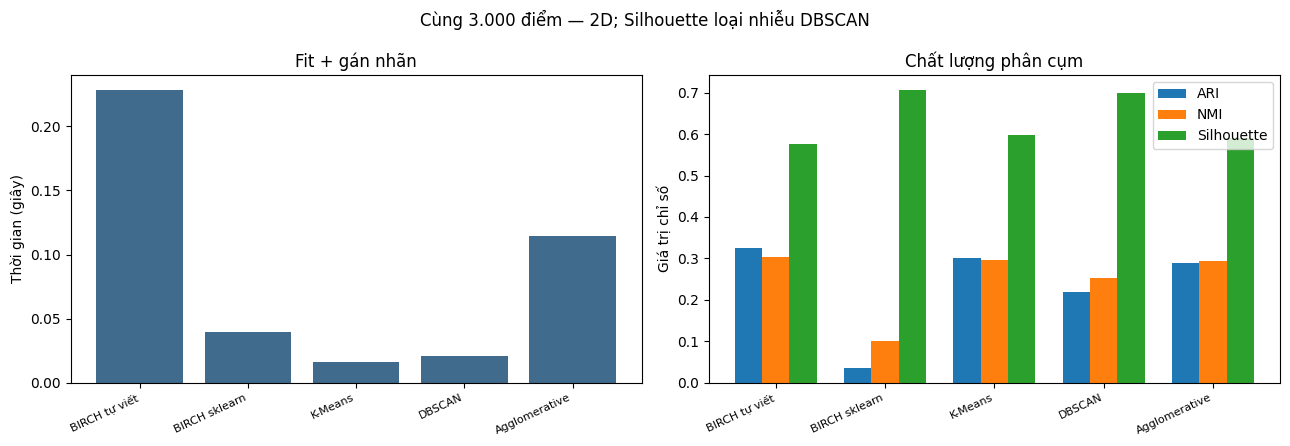

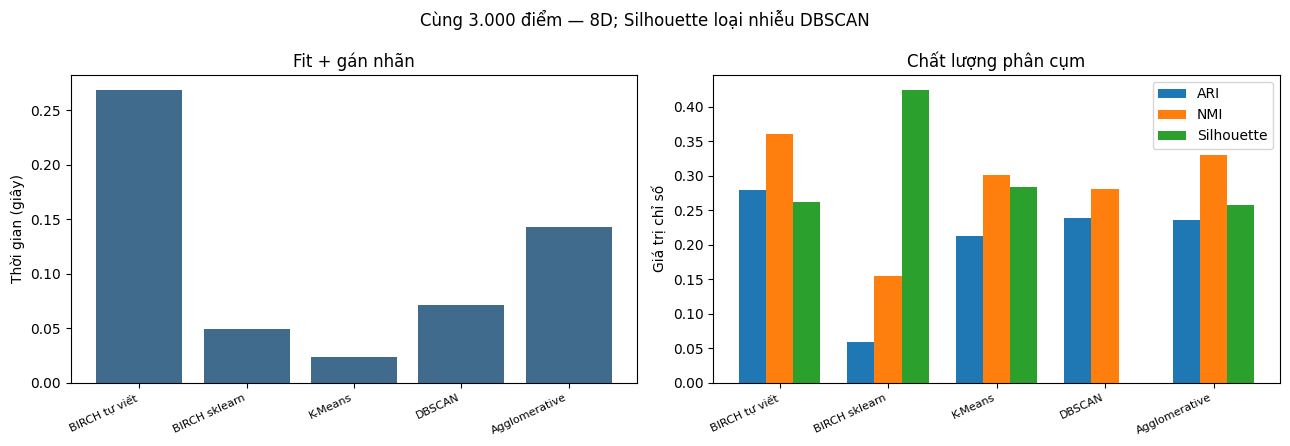

In [19]:
subset_rows = []
for name, X, truth in [("2D", X2, truth2), ("8D", X8, truth8)]:
    chosen = np.sort(np.random.default_rng(SEED).choice(len(X), 3000, replace=False))
    X_sub, y_sub = X[chosen], truth[chosen]
    sil_indices = silhouette_indices(len(X_sub), seed=SEED)
    estimators = [
        ("BIRCH tự viết", Birch(THRESHOLDS[name], B, K, SEED, compute_labels=False)),
        ("BIRCH sklearn", SklearnBirch(threshold=THRESHOLDS[name], branching_factor=B,
                                       n_clusters=K, compute_labels=False)),
        ("K-Means", KMeans(n_clusters=K, n_init=10, random_state=SEED)),
        ("DBSCAN", DBSCAN(eps={"2D": 0.20, "8D": 0.90}[name], min_samples=15, n_jobs=1)),
        ("Agglomerative", AgglomerativeClustering(n_clusters=K, linkage="ward"))]
    for label, estimator in estimators:
        row = run_benchmark(estimator, label, name, X_sub, y_sub, sil_indices, REPEATS)
        subset_rows.append(row)
subset_results = pd.DataFrame(subset_rows)
subset_results.to_csv(OUT / "benchmark_cung_tap_con.csv", index=False)
display(subset_results.round(4))
for name in ["2D", "8D"]:
    show_save(plot_benchmark(subset_results[subset_results.dataset == name],
                            f"Cùng 3.000 điểm — {name}; Silhouette loại nhiễu DBSCAN"),
              f"benchmark_tap_con_{name}.png")

## 11. Đánh giá kết quả

Các bảng thực nghiệm trình bày thời gian, số micro-cluster, ARI, NMI và
Silhouette. Các chỉ số phản ánh những khía cạnh khác nhau của kết quả.
Một cụm rất lớn cùng vài cụm nhỏ ở xa vẫn có thể cho Silhouette cao.

CF Tree giảm số đối tượng ở bước gom cuối, nhưng nhạy với threshold,
thang đo và thứ tự chèn. CF không lưu hình dạng chi tiết của cụm. Phép
`predict` của bản này vẫn so điểm với mọi centroid lá, nên chi phí tăng
theo cả số điểm và số micro-cluster.

## 12. Kết luận

Chương trình cài đặt CF Tree bằng OOP, xử lý hấp thụ, tách lá/nút trong/gốc
và gom cụm bằng weighted K-Means. Ví dụ nhỏ đối chiếu được với phép tính tay;
hai tập lớn kiểm tra khả năng phân cụm trong 2D và 8D.

Các kết quả chỉ phản ánh dữ liệu mô phỏng và cấu hình đã chạy. Hướng thử
nghiệm tiếp theo là thay threshold, đổi thứ tự điểm và đánh giá trên dữ liệu khác.